<a href="https://colab.research.google.com/github/DwiAmandaAP/feature-engineering/blob/main/feature_engineering_units_sold.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Feature Engineering untuk Prediksi Permintaan Produk (`Units_Sold`)
**Dataset:** Bakery Synthetic Dataset (16.569 transaksi, 2023–2024, 3 toko, 35 produk)
**Target:** `Units_Sold` (jumlah unit terjual per produk, per toko, per hari)

Alur : *Feature Understanding → Feature Improvement → Feature Transformation → Feature Generation → Feature Selection*.
Bagian paling penting (dan paling banyak dijelaskan) adalah **Feature Selection**.


In [23]:
import pandas as pd, numpy as np, time, warnings
import matplotlib.pyplot as plt
warnings.filterwarnings('ignore')
from sklearn.ensemble import RandomForestRegressor, HistGradientBoostingRegressor
from sklearn.feature_selection import mutual_info_regression, f_regression, RFECV
from sklearn.inspection import permutation_importance
from sklearn.model_selection import TimeSeriesSplit
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score

PATH = '/content/bakery_synthetic_dataset.csv (1).xlsx'
df = pd.read_excel(PATH)
print(df.shape)
df.head(3)

(16569, 41)


,Transaction_ID,Date,Time,Customer_ID,Customer_Age,Customer_Gender,Product,Category,Quantity,Unit_Price,...,Promotion_Applied,Promotion_Type,Promotion_Score,Customer_Rating,Customer_Segment,Loyalty_Member,Profit,Waste_Cost,Recommended_Product,Recommended_Discount
0,TXN000038,2023-01-01,07:13:00,CUST01289,32,Male,Rusk,Biscuits & Cookies,1,34.79,...,Yes,Festival,100,4,Young Professional,Yes,-4.28,7.71,Rusk,13.0
1,TXN000039,2023-01-01,07:13:00,CUST01289,32,Male,Peanut Butter,Spreads,4,176.62,...,Yes,Festival,100,4,Young Professional,Yes,-105.15,171.43,Bread,9.0
2,TXN000040,2023-01-01,07:13:00,CUST01289,32,Male,Black Forest Cake,Cakes,2,448.03,...,Yes,Festival,100,4,Young Professional,Yes,-461.14,520.00,Soft Drink,14.7


## 1. Feature Understanding

In [24]:
# Kelompokkan fitur berdasarkan tipenya (seperti slide "The types of features")
tipe = {
 'Binary'     : ['Weekend','Promotion_Applied','Loyalty_Member'],
 'Categorical': ['Product','Category','Store_ID','Weather','Season','Day_of_Week','Festival','Promotion_Type',
                 'Payment_Method','Customer_Gender','Customer_Segment','Expiry_Risk'],
 'Discrete'   : ['Quantity','Units_Produced','Units_Sold','Unsold_Units','Stock_Available','Shelf_Life_Days','Customer_Rating','Promotion_Score'],
 'Continuous' : ['Unit_Price','Discount_Percentage','Temperature','Total_Bill','Profit','Waste_Cost'],
 'Complex'    : ['Date','Time','Manufacturing_Date','Expiry_Date'],
}
for k,v in tipe.items(): print(f'{k:12s}: {len(v)} kolom')

print('\nKolom dengan missing value:')
print(df.isna().sum()[df.isna().sum()>0])

Binary      : 3 kolom
Categorical : 12 kolom
Discrete    : 8 kolom
Continuous  : 6 kolom
Complex     : 4 kolom

Kolom dengan missing value:
Festival          15960
Promotion_Type    13209
dtype: int64


In [25]:
# Granularitas data.
# Satu baris = satu transaksi, tetapi Units_Sold adalah angka per (Tanggal, Toko, Produk).
g = df.groupby(['Date','Store_ID','Product'])
print('Maks. nilai Units_Sold berbeda dalam satu grup :', g.Units_Sold.nunique().max())
print('Rata-rata baris per grup                      :', round(g.size().mean(), 2))
print('Jumlah grup (Tanggal, Toko, Produk)           :', g.ngroups)

Maks. nilai Units_Sold berbeda dalam satu grup : 1
Rata-rata baris per grup                      : 1.15
Jumlah grup (Tanggal, Toko, Produk)           : 14405


**Kesimpulan:** `Units_Sold` selalu sama untuk baris dengan (Tanggal, Toko, Produk) yang sama, jadi baris transaksi akan menduplikasi target.
Jika dibiarkan, baris kembar bisa jatuh ke train *dan* test sekaligus (kebocoran data). Karena itu data **diagregasi** menjadi satu baris per (Tanggal, Toko, Produk).

## 2. Feature Improvement (cleaning, imputation, agregasi)

In [26]:
# NaN pada Festival & Promotion_Type dianggap "tidak ada".
print('Festival kosong       :', round(df.Festival.isna().mean()*100,1), '%')
print('Promotion_Type kosong :', round(df.Promotion_Type.isna().mean()*100,1), '%')

agg = g.agg(
    Units_Sold=('Units_Sold','first'), Category=('Category','first'),
    Unit_Price=('Unit_Price','mean'), Discount_Percentage=('Discount_Percentage','mean'),
    Promotion_Applied=('Promotion_Applied', lambda s: int((s=='Yes').any())),
    Promotion_Type=('Promotion_Type','first'), Promotion_Score=('Promotion_Score','mean'),
    Weather=('Weather','first'), Temperature=('Temperature','first'), Season=('Season','first'),
    Day_of_Week=('Day_of_Week','first'), Weekend=('Weekend','first'),
    Festival=('Festival','first'), Shelf_Life_Days=('Shelf_Life_Days','first'),
).reset_index()

# Imputation kategorikal: isi dengan kategori baru "None" (bukan modus!)
agg['Festival'] = agg['Festival'].fillna('None')
agg['Promotion_Type'] = agg['Promotion_Type'].fillna('None')
agg = agg.sort_values('Date').reset_index(drop=True)
print(agg.shape)
agg.isna().sum().sum()

Festival kosong       : 96.3 %
Promotion_Type kosong : 79.7 %
(14405, 17)


np.int64(0)

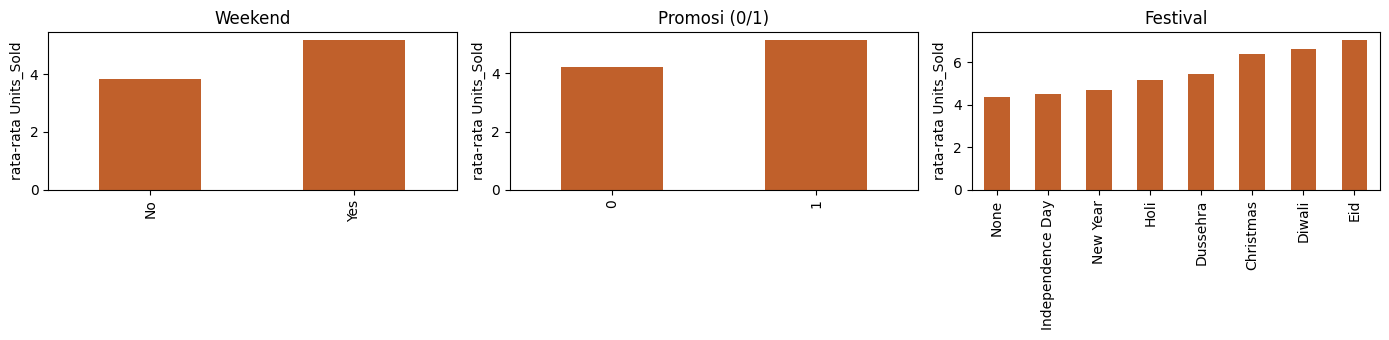

In [27]:
# Eksplorasi singkat: apa yang membedakan permintaan tinggi vs rendah?
fig, ax = plt.subplots(1, 3, figsize=(14, 3.5))
agg.groupby('Weekend').Units_Sold.mean().plot.bar(ax=ax[0], title='Weekend', color='#c0602b')
agg.groupby('Promotion_Applied').Units_Sold.mean().plot.bar(ax=ax[1], title='Promosi (0/1)', color='#c0602b')
agg.groupby('Festival').Units_Sold.mean().sort_values().plot.bar(ax=ax[2], title='Festival', color='#c0602b')
for a in ax: a.set_ylabel('rata-rata Units_Sold'); a.set_xlabel('')
plt.tight_layout(); plt.show()

## 3. Feature Transformation
Kolom teks diubah menjadi angka dengan `astype('category')` dan `.cat.codes`.
Cara ini cocok untuk model berbasis pohon (Random Forest, Gradient Boosting). Untuk model linear, gunakan one-hot encoding.

In [28]:
CAT = ['Store_ID','Product','Category','Promotion_Type','Weather','Season','Day_of_Week','Weekend','Festival']
mapping = {}
for c in CAT:
    col = agg[c].astype('category')
    agg[c + '_code'] = col.cat.codes
    mapping[c] = dict(enumerate(col.cat.categories))
print(mapping['Festival'])
print(mapping['Day_of_Week'])

{0: 'Christmas', 1: 'Diwali', 2: 'Dussehra', 3: 'Eid', 4: 'Holi', 5: 'Independence Day', 6: 'New Year', 7: 'None'}
{0: 'Friday', 1: 'Monday', 2: 'Saturday', 3: 'Sunday', 4: 'Thursday', 5: 'Tuesday', 6: 'Wednesday'}


## 4. Feature Generation
Fitur baru dibuat berdasarkan hasil eksplorasi (weekend, festival, dan promosi menaikkan penjualan) dan logika bisnis.
`Prod_Hist_Mean` memakai `shift(1)` sehingga hanya menggunakan penjualan **hari-hari sebelumnya** (tidak membocorkan target).

In [29]:
agg['Month']        = agg.Date.dt.month
agg['Day']          = agg.Date.dt.day
agg['Is_Weekend']   = (agg.Weekend == 'Yes').astype(int)
agg['Is_Festival']  = (agg.Festival != 'None').astype(int)
agg['Is_Hot']       = (agg.Temperature > 32).astype(int)
agg['Is_Fresh']     = (agg.Shelf_Life_Days <= 3).astype(int)      # produk cepat basi
agg['Is_Payday']    = agg.Day.isin([1,2,25,26,27,28,29,30,31]).astype(int)
agg['Log_Price']    = np.log1p(agg.Unit_Price)
agg['Weekend_x_Festival'] = agg.Is_Weekend * agg.Is_Festival      # interaksi
agg['Discount_x_Weekend'] = agg.Discount_Percentage * agg.Is_Weekend
agg['Prod_Hist_Mean'] = (agg.groupby('Product').Units_Sold
                            .transform(lambda s: s.shift(1).expanding().mean()))
agg['Prod_Hist_Mean'] = agg.Prod_Hist_Mean.fillna(agg.Units_Sold.mean())

BASE = ['Unit_Price','Discount_Percentage','Promotion_Applied','Promotion_Score','Temperature','Shelf_Life_Days'] + [c+'_code' for c in CAT]
GEN  = ['Month','Day','Is_Weekend','Is_Festival','Is_Hot','Is_Fresh','Is_Payday','Log_Price',
        'Weekend_x_Festival','Discount_x_Weekend','Prod_Hist_Mean']
ALL  = BASE + GEN
print(len(BASE), 'fitur dasar +', len(GEN), 'fitur baru =', len(ALL), 'kandidat fitur')

15 fitur dasar + 11 fitur baru = 26 kandidat fitur


## 5. Feature Selection
### 5.0 Pembagian data berdasarkan waktu
Data dibagi berurutan menurut waktu: train → validation → test.
Seleksi fitur hanya boleh memakai train/validation. Test dipakai sekali di akhir untuk perbandingan.

In [30]:
t1, t2 = pd.Timestamp('2024-04-01'), pd.Timestamp('2024-07-01')
train = agg[agg.Date <  t1]
valid = agg[(agg.Date >= t1) & (agg.Date < t2)]
test  = agg[agg.Date >= t2]
trval = agg[agg.Date < t2]
print(len(train), len(valid), len(test))

def evaluate(cols, name, model=None):
    model = model if model is not None else HistGradientBoostingRegressor(random_state=0)
    t = time.time(); model.fit(trval[cols], trval.Units_Sold); dt = time.time() - t
    p = model.predict(test[cols]); y = test.Units_Sold
    return dict(Model=name, N_Fitur=len(cols), RMSE=mean_squared_error(y,p)**.5,
                MAE=mean_absolute_error(y,p), R2=r2_score(y,p), Waktu_fit_s=dt)

base_rmse = mean_squared_error(test.Units_Sold, np.full(len(test), trval.Units_Sold.mean()))**.5
print('RMSE tebakan rata-rata (pembanding):', round(base_rmse,3))

8885 1835 3685
RMSE tebakan rata-rata (pembanding): 3.079


### 5.1 Seleksi berdasarkan domain: buang fitur yang bocor / tidak tersedia saat prediksi
Tujuan model adalah memprediksi permintaan **sebelum** hari berjalan. Kolom yang baru diketahui setelah penjualan terjadi tidak boleh dipakai.
Berikut buktinya pada `Units_Produced` dan `Unsold_Units`.

In [31]:
leak = df.groupby(['Date','Store_ID','Product']).agg(Units_Produced=('Units_Produced','first'),
                                                   Unsold_Units=('Unsold_Units','first')).reset_index()
a2 = agg.merge(leak, on=['Date','Store_ID','Product'])
tr2, te2 = a2[a2.Date < t2], a2[a2.Date >= t2]

def r2_with(cols):
    m = HistGradientBoostingRegressor(random_state=0).fit(tr2[cols], tr2.Units_Sold)
    return r2_score(te2.Units_Sold, m.predict(te2[cols]))

print('R2 fitur sah                    :', round(r2_with(ALL), 3))
print('R2 + Units_Produced             :', round(r2_with(ALL+['Units_Produced']), 3))
print('R2 + Units_Produced + Unsold    :', round(r2_with(ALL+['Units_Produced','Unsold_Units']), 3), ' <- terlalu bagus = kebocoran')

R2 fitur sah                    : 0.138
R2 + Units_Produced             : 0.851
R2 + Units_Produced + Unsold    : 0.985  <- terlalu bagus = kebocoran


`Unsold_Units = Units_Produced − Units_Sold`, jadi memberi `Unsold_Units` ke model sama dengan memberi jawabannya.

| Kolom | Alasan dibuang |
|---|---|
| `Units_Produced`, `Unsold_Units`, `Stock_Available`, `Expiry_Risk` | Diketahui setelah penjualan (`Stock_Available` identik dengan `Unsold_Units`) |
| `Total_Bill`, `Profit`, `Waste_Cost`, `Selling_Price`, `Discount_Amount`, `Quantity` | Hasil dari penjualan itu sendiri |
| `Recommended_Product`, `Recommended_Discount` | Keluaran sistem rekomendasi, dihitung dari stok/penjualan |
| `Customer_*`, `Payment_Method`, `Customer_Rating`, `Loyalty_Member`, `Transaction_ID`, `Time` | Atribut pembeli per transaksi, tidak tersedia saat memprediksi permintaan harian |
| `Manufacturing_Date`, `Expiry_Date` | Redundan: sama dengan `Date` dan `Date + Shelf_Life_Days` |

Kolom-kolom ini tidak ikut `ALL`.

### 5.2 Seleksi redundansi: buang fitur yang saling berkorelasi tinggi
Dua fitur yang hampir kembar tidak menambah informasi, hanya menambah parameter

In [32]:
corr = train[ALL].corr().abs()
pairs = [(a, b, round(corr.loc[a,b],2)) for i,a in enumerate(ALL) for b in ALL[i+1:] if corr.loc[a,b] > 0.8]
pd.DataFrame(pairs, columns=['Fitur A','Fitur B','|korelasi|'])

,Fitur A,Fitur B,|korelasi|
0,Unit_Price,Log_Price,0.92
1,Discount_Percentage,Promotion_Applied,0.84
2,Discount_Percentage,Discount_x_Weekend,0.80
3,Weekend_code,Is_Weekend,1.00
4,Festival_code,Is_Festival,0.88


In [33]:
# Dari tiap pasangan, pertahankan yang lebih mudah dipahami / lebih informatif
drop_redundant = ['Weekend_code',       # identik dengan Is_Weekend
                  'Festival_code',      # hampir sama dgn Is_Festival (kode ordinal juga tidak bermakna urutan)
                  'Unit_Price',         # sudah diwakili Log_Price
                  'Promotion_Applied']  # sudah diwakili Discount_Percentage
SET_B = [c for c in ALL if c not in drop_redundant]
print(len(ALL), '->', len(SET_B), 'fitur')

26 -> 22 fitur


### 5.3 Metode filter: Mutual Information dan F-test
Menilai hubungan tiap fitur dengan target **satu per satu**, tanpa model. Cepat, tetapi tidak melihat interaksi antar fitur.

In [34]:
disc = [c in ['Month','Day'] or c.endswith('_code') or c.startswith('Is_') for c in SET_B]
mi = pd.Series(mutual_info_regression(train[SET_B], train.Units_Sold, discrete_features=disc, random_state=0), SET_B)
f  = pd.Series(f_regression(train[SET_B], train.Units_Sold)[0], SET_B)
filt = pd.DataFrame({'MI': mi, 'F_score': f}).sort_values('MI', ascending=False)
filt.round(3)

,MI,F_score
Temperature,0.117,1.510
Product_code,0.063,69.270
Prod_Hist_Mean,0.049,311.188
Day_of_Week_code,0.036,39.836
Log_Price,0.031,11.904
Promotion_Score,0.030,94.175
Day,0.029,5.846
Discount_x_Weekend,0.029,290.341
Discount_Percentage,0.026,152.569
Category_code,0.026,70.674


In [35]:
SET_MI = list(filt.index[:8])    # top-8 menurut Mutual Information
SET_MI

['Temperature',
 'Product_code',
 'Prod_Hist_Mean',
 'Day_of_Week_code',
 'Log_Price',
 'Promotion_Score',
 'Day',
 'Discount_x_Weekend']

### 5.4 Metode embedded / permutation importance
Fitur penting menurut model. Ada dua cara, dan hasilnya sering **berbeda**:
- *Impurity importance* (bawaan Random Forest): dihitung dari data train, cenderung bias ke fitur kontinu yang punya banyak nilai unik.
- *Permutation importance*: acak nilai satu fitur di data **validation**, lalu lihat seberapa besar error naik. Lebih jujur terhadap kemampuan generalisasi.

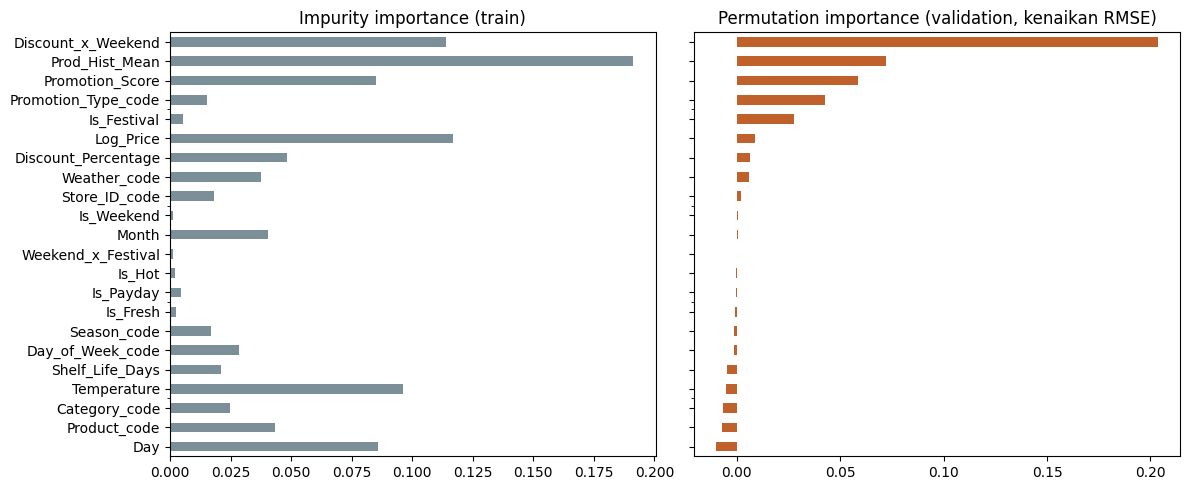

In [17]:
rf = RandomForestRegressor(300, min_samples_leaf=5, n_jobs=-1, random_state=0).fit(train[SET_B], train.Units_Sold)
imp  = pd.Series(rf.feature_importances_, SET_B)
perm = permutation_importance(rf, valid[SET_B], valid.Units_Sold, n_repeats=10, random_state=0,
                              scoring='neg_root_mean_squared_error', n_jobs=-1)
perm = pd.Series(perm.importances_mean, SET_B)

order = perm.sort_values().index
fig, ax = plt.subplots(1, 2, figsize=(12, 5), sharey=True)
imp[order].plot.barh(ax=ax[0], color='#7b8f99', title='Impurity importance (train)')
perm[order].plot.barh(ax=ax[1], color='#c0602b', title='Permutation importance (validation, kenaikan RMSE)')
plt.tight_layout(); plt.show()

In [18]:
SET_PERM = list(perm[perm > 0.01].sort_values(ascending=False).index)   # naik RMSE > 0.01 jika diacak
print(len(SET_PERM), 'fitur terpilih:', SET_PERM)

5 fitur terpilih: ['Discount_x_Weekend', 'Prod_Hist_Mean', 'Promotion_Score', 'Promotion_Type_code', 'Is_Festival']


### 5.5 Metode wrapper: RFECV (Recursive Feature Elimination with CV)
Membuang fitur terlemah secara bertahap dan memilih jumlah fitur terbaik lewat cross-validation berurutan waktu (`TimeSeriesSplit`). Paling lambat, tetapi memperhitungkan kombinasi fitur.

In [19]:
rfecv = RFECV(RandomForestRegressor(100, min_samples_leaf=5, n_jobs=-1, random_state=0), step=2,
              cv=TimeSeriesSplit(3), scoring='neg_root_mean_squared_error', min_features_to_select=4)
rfecv.fit(trval[SET_B], trval.Units_Sold)
SET_RFE = list(np.array(SET_B)[rfecv.support_])
print(len(SET_RFE), 'fitur terpilih:', SET_RFE)

6 fitur terpilih: [np.str_('Promotion_Score'), np.str_('Temperature'), np.str_('Day'), np.str_('Log_Price'), np.str_('Discount_x_Weekend'), np.str_('Prod_Hist_Mean')]


### 5.6 Membandingkan semua hasil seleksi di data test
Sesuai slide, tujuan seleksi: **akurasi, interpretabilitas, memori, dan waktu training**. Perbandingan memakai model yang sama.

In [20]:
hasil = pd.DataFrame([
    evaluate(BASE,      'A. Fitur dasar (sebelum generation)'),
    evaluate(ALL,       'B. Semua fitur (dasar + baru)'),
    evaluate(SET_B,     'C. Setelah buang redundan'),
    evaluate(SET_MI,    'D. Filter: Mutual Information top-8'),
    evaluate(SET_PERM,  'E. Permutation importance'),
    evaluate(SET_RFE,   'F. RFECV'),
]).set_index('Model')
hasil['Penurunan fitur vs B'] = ((1 - hasil.N_Fitur / len(ALL))*100).round(0).astype(int).astype(str) + '%'
print('RMSE tebakan rata-rata:', round(base_rmse,3))
hasil.round(3)

RMSE tebakan rata-rata: 3.079


,N_Fitur,RMSE,MAE,R2,Waktu_fit_s,Penurunan fitur vs B
Model,,,,,,
A. Fitur dasar (sebelum generation),15,2.854,2.143,0.141,0.350,42%
B. Semua fitur (dasar + baru),26,2.859,2.146,0.138,0.630,0%
C. Setelah buang redundan,22,2.867,2.153,0.133,0.471,15%
D. Filter: Mutual Information top-8,8,2.917,2.177,0.103,0.261,69%
E. Permutation importance,5,2.865,2.146,0.134,0.178,81%
F. RFECV,6,2.911,2.174,0.106,0.214,77%


In [21]:
best = hasil.RMSE.idxmin()
print('Set fitur dengan RMSE terkecil:', best)
print(hasil.loc[best, ['N_Fitur','RMSE','MAE','R2']].round(3).to_dict())

Set fitur dengan RMSE terkecil: A. Fitur dasar (sebelum generation)
{'N_Fitur': 15, 'RMSE': 2.853615616594789, 'MAE': 2.142606025612887, 'R2': 0.14121934944147585}


### 5.7 Model akhir dan fitur yang dipakai
Pilih set fitur dengan **error rendah, jumlah fitur sedikit, dan masuk akal secara bisnis**.

In [22]:
FINAL = SET_PERM
m = HistGradientBoostingRegressor(random_state=0).fit(trval[FINAL], trval.Units_Sold)
pred = m.predict(test[FINAL])
res = test[['Date','Store_ID','Product','Units_Sold']].assign(Prediksi=pred.round(1))
print('RMSE:', round(mean_squared_error(test.Units_Sold, pred)**.5, 3),
      '| MAE:', round(mean_absolute_error(test.Units_Sold, pred), 3),
      '| R2:', round(r2_score(test.Units_Sold, pred), 3))
res.sample(8, random_state=1)

RMSE: 2.865 | MAE: 2.146 | R2: 0.134


,Date,Store_ID,Product,Units_Sold,Prediksi
12071,2024-09-06,ST01,Chocolate Cake,6,3.2
13683,2024-11-24,ST01,Cold Coffee,3,5.4
13099,2024-10-27,ST01,Bread,10,8.1
12831,2024-10-15,ST02,Jam,3,3.4
11574,2024-08-12,ST01,Chocolate Cupcake,4,3.6
12757,2024-10-12,ST03,Eggs,2,4.0
11893,2024-08-29,ST01,Rusk,7,3.6
11493,2024-08-09,ST01,Brown Bread,2,3.6


## 6. Kesimpulan
1. **Granularitas data penting.** `Units_Sold` konstan per (Tanggal, Toko, Produk), jadi data diagregasi dari 16.569 menjadi 14.405 baris sebelum dibagi train/test.
2. **Kebocoran data adalah jebakan terbesar.** Menambahkan `Units_Produced` menaikkan R² dari sekitar 0,14 menjadi 0,85, dan menambahkan `Unsold_Units` menjadi 0,99. Itu bukan model yang bagus, melainkan jawaban yang ikut masuk sebagai fitur.
3. **Sinyal pada dataset sintetis ini lemah.** R² yang jujur hanya sekitar 0,13–0,14 (RMSE turun dari 3,08 ke sekitar 2,86). Ini wajar karena datanya sintetis dan perlu dijelaskan di laporan, bukan disembunyikan.
4. **Feature generation tidak otomatis meningkatkan akurasi.** Set A (15 fitur dasar) sama baiknya dengan set B (26 fitur). Penambahan fitur baru hanya terbukti berguna jika lolos seleksi.
5. **Feature selection berhasil mengurangi fitur tanpa menurunkan akurasi.** Permutation importance memilih 5 dari 26 fitur (81% lebih sedikit) dengan RMSE 2,865 vs 2,859, dan waktu training lebih cepat. Model jadi lebih mudah dijelaskan: diskon pada akhir pekan, rata-rata historis produk, skor promosi, jenis promosi, dan hari festival.
6. **Metode seleksi bisa memberi jawaban berbeda.** `Temperature` menempati peringkat atas pada Mutual Information dan impurity importance, tetapi permutation importance menunjukkan fitur ini tidak membantu prediksi di data validation. Itu tanda bias terhadap fitur kontinu. Karena itu hasil seleksi sebaiknya selalu dicek dengan evaluasi pada data yang tidak dipakai untuk melatih.

**Saran pengembangan:** tambahkan fitur lag per produk dan toko (penjualan 7 hari terakhir), lalu coba model lain seperti LightGBM atau regresi Poisson, karena `Units_Sold` berupa hitungan.